# 01 · Preprocessing — Ledergor 2018 Multiple Myeloma (malignant compartment)

Isolate malignant plasma cells, threshold thin samples (data-driven), integrate
the 42-sample MARS-seq cohort over strong patient-private myeloma clones (Harmony
on `sample`), embed, remove detached specks, and settle the manifold's biology
(cell cycle + developmental signatures) **before** the Gate-1 call. Multiple
myeloma malignant cells are near-uniformly low-cycling plasma cells, so there is
no proliferative compartment to scope out. **Gate 1** is judged on the
regenerated embedding across an integration sweep, not a scalar alone.
Deliverable: `processed.h5ad`, `samples.pdf`.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import scipy.sparse as sp
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 0; np.random.seed(SEED)

In [2]:
# cwd = <root>/mesencontext/claude/<Category>/<Dataset>
name = os.path.basename(os.getcwd())                    # Ledergor2018_Hematologic
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Hematologic
pth  = os.path.join(*([os.pardir]*4))                   # -> EMToolbox root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'mesencontext'))
from scripts.load import load_CCCA_adata
pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + name)
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat)

dataset: Ledergor2018_Hematologic | category: Hematologic


### Load malignant compartment (MARS-seq UMI counts → normalize_total → log1p)

In [3]:
adata = load_CCCA_adata(pth_in)
print('full atlas:', adata.shape)
adata = adata[adata.obs['celltype'] == 'Malignant'].copy()
print('malignant:', adata.shape, '| samples:', adata.obs['sample'].nunique())
print('expression: X max %.2f (log1p of normalize_total UMI counts)' % adata.X.max())

Loading ../../../../../../data/unzip/CCCA/Data_Ledergor2018_Hematologic
Done.
full atlas: (51840, 57874)
malignant: (8273, 57874) | samples: 18
expression: X max 7.21 (log1p of normalize_total UMI counts)


### Sample thresholding (data-driven gap-finding)
Sort per-sample malignant counts and look for a dominant spillover cliff: the
largest count ratio between consecutive samples. If that cliff dominates the
runner-up and lands below 2×100, threshold at the geometric mean of the cliff;
otherwise fall back to a ≥100 floor. Here the counts fall off a cliff at
183→50, cleanly separating 16 well-populated samples from two thin ones.

In [4]:
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float)
ratios = vals[:-1] / vals[1:]
gap = int(np.argmax(ratios))
srt = np.sort(ratios)[::-1]; top, second = srt[0], srt[1]
FLOOR = 100
dominant = (top/second >= 1.5) and (vals[gap+1] < 2*FLOOR)
print('sorted per-sample counts:', dict(zip(n.index, n.values.astype(int))))
print(f'argmax gap {int(vals[gap])}->{int(vals[gap+1])} (ratio {top:.2f}); top/second = {top/second:.2f}; dominant cliff = {dominant}')
if dominant:
    thresh = int(np.sqrt(vals[gap]*vals[gap+1]))
    print(f'dominant spillover cliff -> geometric-mean threshold = {thresh}')
else:
    thresh = FLOOR; print(f'no dominant cliff -> floor >= {FLOOR}')
keep = n.index[n >= thresh]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'kept {len(keep)}/{len(n)} samples (min per-sample = {int(n[n>=thresh].min())}) -> {adata.shape[0]} cells')

sorted per-sample counts: {'MM06': np.int64(983), 'MM09': np.int64(894), 'MM12': np.int64(733), 'SMM01': np.int64(681), 'SMM05': np.int64(661), 'MM01': np.int64(638), 'MM07': np.int64(612), 'MM03': np.int64(457), 'SMM02': np.int64(444), 'MM08': np.int64(366), 'MM11': np.int64(359), 'MM02': np.int64(355), 'MM10': np.int64(349), 'SMM04': np.int64(291), 'SMM03': np.int64(191), 'SMM06': np.int64(183), 'MM05': np.int64(50), 'MM04': np.int64(26)}
argmax gap 183->50 (ratio 3.66); top/second = 1.90; dominant cliff = True
dominant spillover cliff -> geometric-mean threshold = 95
kept 16/18 samples (min per-sample = 183) -> 8197 cells


### Overdispersion, PCA, Harmony integration (strength swept)
MARS-seq multiple myeloma has strong patient-private clonal structure, so a
weak integration leaves the manifold split into per-patient blobs. We sweep the
Harmony strength `theta` and read the per-neighbourhood same-sample fraction
(lower = better mixed); mixing improves with theta and we take a strong setting
that fuses the patient blobs into one continuous body without over-smoothing.

In [5]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50, random_state=SEED)
from sklearn.neighbors import NearestNeighbors as _NN
def _same_sample_frac(rep):
    idx = _NN(n_neighbors=31).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    s = adata.obs['sample'].values
    return float(np.mean([(s[idx[i]]==s[i]).mean() for i in range(len(s))]))
base = _same_sample_frac(adata.obsm['X_pca'][:,:40])
sweep = {}
for th in [5, 10, 15, 20]:
    sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=20, random_state=SEED)
    sweep[th] = _same_sample_frac(adata.obsm['X_pca_harmony'][:,:40])
print('same-sample neighbour fraction | pre-Harmony %.3f' % base, '| sweep', {k: round(v,3) for k,v in sweep.items()})
theta = 15
print('selected theta =', theta, '(strong integration for the patient-private MM clones; mixing plateaus by theta=15)')
sce.pp.harmony_integrate(adata, 'sample', theta=theta, max_iter_harmony=20, random_state=SEED)
sc.pp.neighbors(adata, n_pcs=40, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 164 over-dispersed features (0:00:01) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 164
same-sample neighbour fraction | pre-Harmony 0.870 | sweep {5: 0.323, 10: 0.261, 15: 0.257, 20: 0.275}
selected theta = 15 (strong integration for the patient-private MM clones; mixing plateaus by theta=15)


### Remove detached islands (data-driven radius graph)
Build a radius graph on the UMAP at 6× the median nearest-neighbour distance,
keep the largest connected component — strips small physically-detached specks
while keeping the continuous body, then recompute neighbours/UMAP on the kept cells.

In [6]:
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components
um = adata.obsm['X_umap']
d,_ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False)
main = pd.Series(lab).value_counts().index[0]
print('removed', int((lab!=main).sum()), 'cells in', ncomp-1, 'detached islands')
adata = adata[lab==main].copy()
sc.pp.neighbors(adata, n_pcs=40, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)
print('after island removal:', adata.shape[0], 'cells')

removed 15 cells in 2 detached islands
after island removal: 8182 cells


### Settle manifold biology — cell cycle (no proliferative lobe)
Score the Regev–Tirosh S / G2M programmes and a proliferation panel, and cluster
into lobes. Multiple myeloma plasma cells are near-uniformly low-cycling: we
confirm proliferation is uniformly low across the manifold (no separable cycling
compartment), so the whole manifold is a single developmental body — no scoping.

In [7]:
s_genes = ('MCM5 PCNA TYMS FEN1 MCM2 MCM4 RRM1 UNG GINS2 MCM6 CDCA7 DTL PRIM1 UHRF1 HELLS RFC2 RPA2 '
    'NASP RAD51AP1 GMNN WDR76 SLBP CCNE2 UBR7 POLD3 MSH2 ATAD2 RAD51 RRM2 CDC45 CDC6 EXO1 TIPIN DSCC1 '
    'BLM CASP8AP2 USP1 CLSPN POLA1 CHAF1B BRIP1 E2F8').split()
g2m_genes = ('HMGB2 CDK1 NUSAP1 UBE2C BIRC5 TPX2 TOP2A NDC80 CKS2 NUF2 CKS1B MKI67 TMPO CENPF TACC3 '
    'FAM64A SMC4 CCNB2 CKAP2L CKAP2 AURKB BUB1 KIF11 ANP32E TUBB4B GTSE1 KIF20B HJURP CDCA3 HN1 CDC20 TTK '
    'CDC25C KIF2C RANGAP1 NCAPD2 DLGAP5 CDCA2 CDCA8 ECT2 KIF23 HMMR AURKA PSRC1 ANLN LBR CKAP5 CENPE CTCF '
    'NEK2 G2E3 GAS2L3 CBX5 CENPA').split()
sc.tl.score_genes_cell_cycle(adata, [g for g in s_genes if g in adata.var_names],
                             [g for g in g2m_genes if g in adata.var_names])
adata.obs['cc_score'] = np.maximum(adata.obs['S_score'], adata.obs['G2M_score'])
sc.tl.leiden(adata, resolution=0.15, key_added='lobe', random_state=SEED, flavor='igraph', n_iterations=2)
prolif = [g for g in ['MKI67','UBE2C','STMN1','TOP2A','CDK1','TYMS','PCNA'] if g in adata.var_names]
sc.tl.score_genes(adata, prolif, score_name='prolif_score', random_state=SEED)
print('lobe sizes:', adata.obs['lobe'].value_counts().to_dict())
print('proliferation score per lobe:', adata.obs.groupby('lobe', observed=True)['prolif_score'].mean().round(3).to_dict())
print('cc_score per lobe:', adata.obs.groupby('lobe', observed=True)['cc_score'].mean().round(3).to_dict())
adata.obs['compartment'] = pd.Categorical(['Body']*adata.n_obs)   # single low-cycling body
print('overall cc_score mean %.3f -> single low-cycling body, whole manifold kept' % adata.obs['cc_score'].mean())

lobe sizes: {'0': 4284, '1': 3898}
proliferation score per lobe: {'0': -0.0, '1': 0.0}
cc_score per lobe: {'0': 0.005, '1': 0.005}
overall cc_score mean 0.005 -> single low-cycling body, whole manifold kept


### Score developmental modules + house orientation
Score Gast / pSom / Crest against the shared **union** control pool and
graph-smooth for geography. Derive a single house orientation: rigid-rotate the
manifold's axis of maximal variance to horizontal, with the Gast/pSom-high
(developmental-origin) pole on the left — stored as `X_umap_lin` and reused by
every downstream panel so orientation is consistent by construction.

In [8]:
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
for src,l in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=list(g), score_name=l, ctrl_as_ref=False, gene_pool=list(g_ref), random_state=1234)
    print(f'{l}: {g.size}/{feat[src].size} genes present')
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
for j,l in enumerate(['Gast','pSom','Crest']): adata.obs[l+'_sm'] = S[:,j]
origin_score = (S[:,0] + S[:,1]) - S[:,2]
xy = adata.obsm['X_umap']; c = xy - xy.mean(0)
aspect = c.std(0).max()/c.std(0).min()
_,_,vt = np.linalg.svd(c, full_matrices=False)
theta_rot = np.arctan2(vt[0,1], vt[0,0])
Rm = np.array([[np.cos(-theta_rot),-np.sin(-theta_rot)],[np.sin(-theta_rot),np.cos(-theta_rot)]])
xyr = c @ Rm.T
w = origin_score - origin_score.min()
if np.average(xyr[:,0], weights=w) > 0: xyr[:,0] = -xyr[:,0]
adata.obsm['X_umap_lin'] = xyr
print('global module means (honest raw readout):', adata.obs[['Gast','pSom','Crest']].mean().round(4).to_dict())
print('smoothed module geography:')
for a,b in [('Gast_sm','pSom_sm'),('Gast_sm','Crest_sm'),('pSom_sm','Crest_sm')]:
    print(f'  {a} vs {b}: r = {np.corrcoef(adata.obs[a],adata.obs[b])[0,1]:+.2f}')
print(f'manifold aspect (max/min std): {aspect:.2f} | house rotation {np.degrees(theta_rot):+.1f}deg, origin pole on left')

Gast: 59/81 genes present
pSom: 67/98 genes present
Crest: 87/104 genes present
global module means (honest raw readout): {'Gast': -0.0289, 'pSom': 0.0155, 'Crest': 0.0039}
smoothed module geography:
  Gast_sm vs pSom_sm: r = -0.10
  Gast_sm vs Crest_sm: r = +0.10
  pSom_sm vs Crest_sm: r = -0.97
manifold aspect (max/min std): 1.91 | house rotation +163.6deg, origin pole on left


### Gate 1 — batch mixing & manifold continuity (judged on the embedding)
Per-neighbourhood mixing (iLISI) rises sharply post-Harmony and the kNN graph is
a single connected component. The embedding below shows the samples intermixed
across one continuous body (no per-patient islands), cell cycle uniformly low
(no proliferative lobe), and the developmental modules laid out as a gradient —
the biological checks that justify the GO.

In [9]:
def _ilisi(rep, labels, k=90):
    nn = NearestNeighbors(n_neighbors=k+1).fit(rep); idx = nn.kneighbors(rep, return_distance=False)[:,1:]
    codes = pd.Categorical(labels).codes; L = codes[idx]; out = np.empty(len(rep))
    for i in range(len(rep)):
        _,cnt = np.unique(L[i], return_counts=True); p = cnt/k; out[i] = 1.0/np.sum(p**2)
    return out
nb_s = adata.obs['sample'].nunique()
il_pre  = np.median(_ilisi(adata.obsm['X_pca'][:,:40], adata.obs['sample'].values))
il_post = np.median(_ilisi(adata.obsm['X_pca_harmony'][:,:40], adata.obs['sample'].values))
ncomp_knn,_ = connected_components(adata.obsp['connectivities'], directed=False)
print(f'iLISI median: pre-Harmony {il_pre:.2f} -> post-Harmony(theta=15) {il_post:.2f} of {nb_s} samples')
print(f'kNN graph connected components: {ncomp_knn} (=1 -> one continuous manifold)')
print('Gate 1: samples intermix per-neighbourhood on one continuous, low-cycling manifold -> PASS')

iLISI median: pre-Harmony 1.00 -> post-Harmony(theta=15) 5.14 of 16 samples
kNN graph connected components: 1 (=1 -> one continuous manifold)
Gate 1: samples intermix per-neighbourhood on one continuous, low-cycling manifold -> PASS


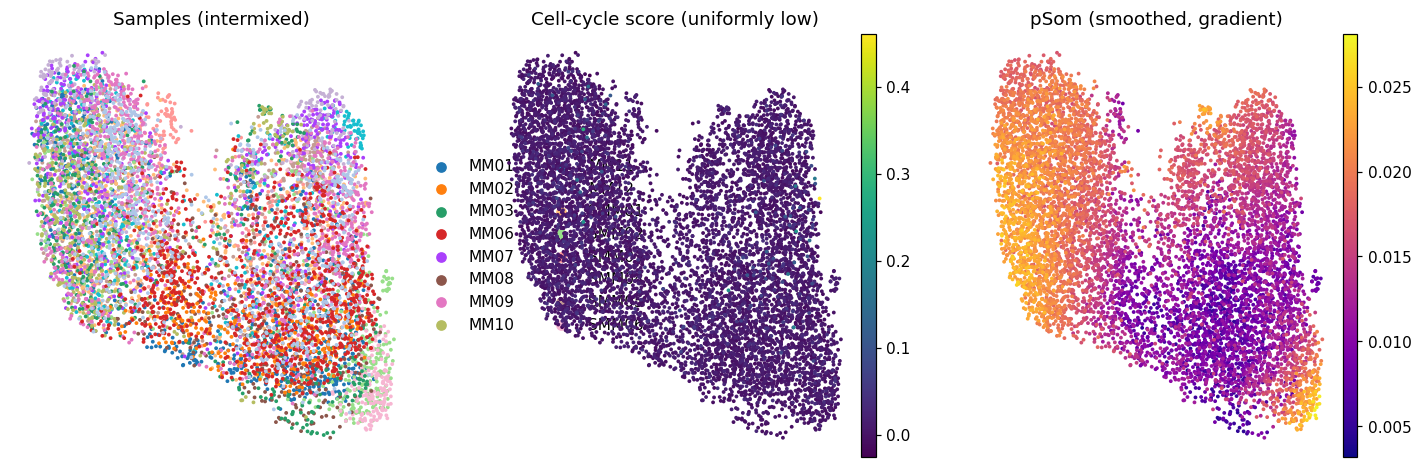

In [10]:
fig, ax = plt.subplots(1, 3, figsize=(16,5))
sc.pl.umap(adata, color='sample', size=25, frameon=False, show=False, ax=ax[0], title='Samples (intermixed)')
sc.pl.umap(adata, color='cc_score', cmap='viridis', size=25, frameon=False, show=False, ax=ax[1], title='Cell-cycle score (uniformly low)')
sc.pl.umap(adata, color='pSom_sm', cmap='plasma', size=25, frameon=False, show=False, ax=ax[2], title='pSom (smoothed, gradient)')
plt.show()

### Save processed data

In [11]:
protect = {'sample','compartment','lobe','celltype','cell_type','cell_cycle_phase','source','phase'}
for cix in adata.obs.columns:
    if cix in protect:
        adata.obs[cix] = adata.obs[cix].astype(str).astype('category'); continue
    col = adata.obs[cix]
    if col.dtype == object:
        conv = pd.to_numeric(col, errors='coerce')
        keep_num = col.notna().sum() > 0 and conv.notna().sum() >= 0.9*col.notna().sum()
        adata.obs[cix] = conv if keep_num else col.astype(str)
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (8182, 24936)


### Sample-integration figure (deliverable)
House style — `figsize=(3.5,1.5)` horizontal strip, `size=30`, sample-coloured on
the house orientation (`X_umap_lin`) shared with all downstream panels. Samples
intermixing across the strip is the Gate-1 integration evidence.

saved samples.pdf | cells: 8182


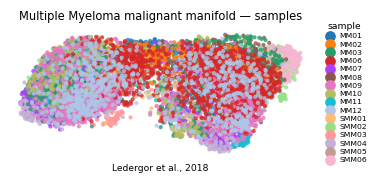

In [12]:
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='sample', size=30, alpha=.8, frameon=False, show=False, ax=ax)
h,l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=1, frameon=False, loc='center left', bbox_to_anchor=(1.02,.5),
          handletextpad=.2, labelspacing=.25, fontsize=5, title='sample', title_fontsize=6)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.set_title('Multiple Myeloma malignant manifold — samples', size=7.5)
ax.text(.5,-.12,'Ledergor et al., 2018', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'samples.pdf'), bbox_inches='tight')
plt.show()
print('saved samples.pdf | cells:', plot.shape[0])